# QPSK and OFDM Basics

## Objective

This notebook develops the digital-communications foundation for the wireless channel model.

The goals are to:

1. Generate a reproducible sequence of binary data.
2. Map pairs of bits to QPSK symbols.
3. Visualize the QPSK constellation.
4. Demodulate the symbols and verify error-free recovery in an ideal channel.
5. Place QPSK symbols onto OFDM subcarriers.
6. Convert the signal from the frequency domain to the time domain using the inverse fast Fourier transform (IFFT).
7. Recover the subcarrier symbols using the fast Fourier transform (FFT).
8. Verify that the transmitted bit sequence is recovered with zero bit errors in an ideal channel.

This ideal transmitter-receiver chain will provide the reference case before noise, multipath propagation, and equalization are introduced.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Reproducible random-number generator
rng = np.random.default_rng(42)

## Generating Binary Data

Digital communication begins with a sequence of binary values.

QPSK carries **two bits per symbol**, so the number of generated bits must be even.

In [2]:
num_bits = 200

bits = rng.integers(
    low=0,
    high=2,
    size=num_bits
)

print("Number of bits:", len(bits))
print("First 20 bits:", bits[:20])

Number of bits: 200
First 20 bits: [0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0]


## QPSK Symbol Mapping

Quadrature Phase Shift Keying (QPSK) represents two bits with one complex-valued symbol.

The two components of each symbol are:

- the in-phase component, $I$
- the quadrature component, $Q$

This notebook uses the following Gray-coded mapping:

$$
00 \rightarrow \frac{1+j}{\sqrt{2}}
$$

$$
01 \rightarrow \frac{1-j}{\sqrt{2}}
$$

$$
11 \rightarrow \frac{-1-j}{\sqrt{2}}
$$

$$
10 \rightarrow \frac{-1+j}{\sqrt{2}}
$$

The factor $1/\sqrt{2}$ normalizes each QPSK symbol to unit energy:

$$
|s|^2 = I^2 + Q^2 = 1.
$$

Gray coding is useful because neighboring constellation points differ by only one bit.

In [3]:
# Group the bit sequence into pairs
bit_pairs = bits.reshape(-1, 2)

# Map the first bit to the in-phase component
I = 1 - 2 * bit_pairs[:, 0]

# Map the second bit to the quadrature component
Q = 1 - 2 * bit_pairs[:, 1]

# Construct normalized complex QPSK symbols
qpsk_symbols = (I + 1j * Q) / np.sqrt(2)

print("Number of QPSK symbols:", len(qpsk_symbols))
print("\nFirst 10 bit pairs:")
print(bit_pairs[:10])

print("\nFirst 10 QPSK symbols:")
print(qpsk_symbols[:10])

Number of QPSK symbols: 100

First 10 bit pairs:
[[0 1]
 [1 0]
 [0 1]
 [0 1]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [1 0]
 [1 0]]

First 10 QPSK symbols:
[ 0.70710678-0.70710678j -0.70710678+0.70710678j  0.70710678-0.70710678j
  0.70710678-0.70710678j  0.70710678+0.70710678j -0.70710678-0.70710678j
 -0.70710678-0.70710678j -0.70710678-0.70710678j -0.70710678+0.70710678j
 -0.70710678+0.70710678j]


In [4]:
# Verify that all QPSK symbols have unit energy
symbol_energies = np.abs(qpsk_symbols) ** 2

print("Average symbol energy:", np.mean(symbol_energies))
print("Minimum symbol energy:", np.min(symbol_energies))
print("Maximum symbol energy:", np.max(symbol_energies))

Average symbol energy: 1.0
Minimum symbol energy: 1.0
Maximum symbol energy: 1.0


## QPSK Constellation

A constellation diagram represents each complex-valued QPSK symbol in the in-phase/quadrature plane.

The horizontal axis represents the in-phase component $I$, while the vertical axis represents the quadrature component $Q$.

For normalized QPSK, the four ideal constellation points are located at

$$
\left(\pm\frac{1}{\sqrt{2}},\,
\pm\frac{1}{\sqrt{2}}\right).
$$

Because this is an ideal channel with no noise or distortion, every transmitted symbol should fall exactly on one of these four points.

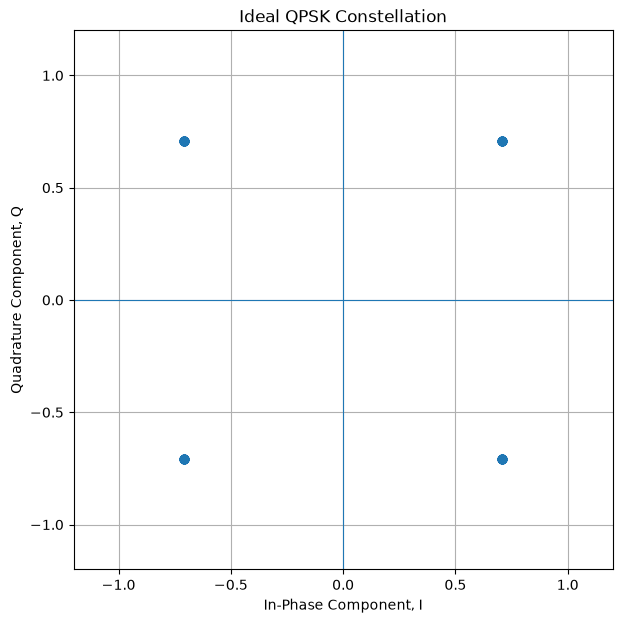

In [5]:
plt.figure(figsize=(7, 7))

plt.scatter(
    qpsk_symbols.real,
    qpsk_symbols.imag
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("In-Phase Component, I")
plt.ylabel("Quadrature Component, Q")
plt.title("Ideal QPSK Constellation")

plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)

plt.grid(True)
plt.gca().set_aspect("equal", adjustable="box")

plt.savefig(
    "../results/qpsk_constellation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Ideal QPSK Demodulation

In an ideal channel, the received QPSK symbols are identical to the transmitted symbols.

Because the four QPSK constellation points lie in different quadrants, the original bits can be recovered using the signs of the in-phase and quadrature components.

For the mapping used in this notebook:

- $I > 0$ corresponds to a first bit of 0.
- $I < 0$ corresponds to a first bit of 1.
- $Q > 0$ corresponds to a second bit of 0.
- $Q < 0$ corresponds to a second bit of 1.

The recovered bits can then be compared directly with the transmitted bits to calculate the bit error rate (BER):

$$
\mathrm{BER}
=
\frac{\text{number of incorrect bits}}
{\text{total number of transmitted bits}}.
$$

For an ideal channel with no noise or distortion, the expected BER is zero.

In [6]:
# Recover the two bits from each QPSK symbol

recovered_first_bits = (qpsk_symbols.real < 0).astype(int)
recovered_second_bits = (qpsk_symbols.imag < 0).astype(int)

recovered_bit_pairs = np.column_stack(
    (recovered_first_bits, recovered_second_bits)
)

# Convert the bit pairs back into one-dimensional binary data
recovered_bits = recovered_bit_pairs.reshape(-1)

# Compare transmitted and recovered bits
bit_errors = np.count_nonzero(bits != recovered_bits)
ber = bit_errors / len(bits)

print("Number of transmitted bits:", len(bits))
print("Number of recovered bits:", len(recovered_bits))
print("Bit errors:", bit_errors)
print(f"Bit error rate (BER): {ber:.6f}")

print("\nFirst 20 transmitted bits:")
print(bits[:20])

print("\nFirst 20 recovered bits:")
print(recovered_bits[:20])

# Reproducibility / correctness check
assert np.array_equal(bits, recovered_bits)

Number of transmitted bits: 200
Number of recovered bits: 200
Bit errors: 0
Bit error rate (BER): 0.000000

First 20 transmitted bits:
[0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0]

First 20 recovered bits:
[0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0]


## QPSK Validation

The QPSK receiver recovered all transmitted bits correctly in the ideal channel, producing a bit error rate of zero.

This validates the QPSK modulation and demodulation stages before they are incorporated into the OFDM transmitter-receiver chain.

Later experiments will introduce channel impairments such as noise and multipath propagation, which will cause the received constellation points to move away from their ideal locations and may produce bit errors.

## OFDM Transmitter

Orthogonal Frequency Division Multiplexing (OFDM) transmits data on many orthogonal subcarriers simultaneously.

Each subcarrier carries one complex modulation symbol. In this notebook, the subcarrier symbols are QPSK symbols.

An OFDM transmitter can be represented as

$$
X[k]
\;\xrightarrow{\mathrm{IFFT}}\;
x[n],
$$

where:

- $X[k]$ represents the complex QPSK symbols assigned to frequency-domain subcarriers,
- $x[n]$ represents the corresponding time-domain OFDM waveform.

For an $N$-subcarrier OFDM symbol,

$$
x[n]
=
\frac{1}{N}
\sum_{k=0}^{N-1}
X[k]e^{j2\pi kn/N}.
$$

The inverse fast Fourier transform (IFFT) efficiently performs this conversion from the frequency domain to the time domain.

A simplified 64-point OFDM system is used here to establish the basic transmitter-receiver chain. For this introductory model, the available FFT bins are treated as data-bearing subcarriers; practical wireless systems typically reserve some bins for guard bands, DC, and pilot signals.

In [7]:
# Number of subcarriers in each OFDM symbol
N_fft = 64

# Number of QPSK symbols available
num_qpsk_symbols = len(qpsk_symbols)

# Determine how many OFDM symbols are needed
num_ofdm_symbols = int(np.ceil(num_qpsk_symbols / N_fft))

# Pad with zeros so the QPSK sequence fills complete OFDM blocks
num_padding_symbols = num_ofdm_symbols * N_fft - num_qpsk_symbols

padded_qpsk_symbols = np.pad(
    qpsk_symbols,
    (0, num_padding_symbols),
    mode="constant"
)

# Each row now represents one frequency-domain OFDM symbol
ofdm_frequency_symbols = padded_qpsk_symbols.reshape(
    num_ofdm_symbols,
    N_fft
)

print("QPSK symbols:", num_qpsk_symbols)
print("OFDM subcarriers per symbol:", N_fft)
print("Number of OFDM symbols:", num_ofdm_symbols)
print("Padding symbols added:", num_padding_symbols)
print("OFDM frequency-domain array shape:", ofdm_frequency_symbols.shape)

QPSK symbols: 100
OFDM subcarriers per symbol: 64
Number of OFDM symbols: 2
Padding symbols added: 28
OFDM frequency-domain array shape: (2, 64)


### Frequency Domain to Time Domain

The QPSK symbols currently represent the values assigned to OFDM subcarriers in the frequency domain.

Applying a 64-point IFFT to each OFDM block combines those subcarriers into a time-domain waveform that can be transmitted.

No channel impairments are introduced yet. This allows the transmitter and receiver processing to be validated under ideal conditions.

In [8]:
# Convert each frequency-domain OFDM symbol to the time domain
ofdm_time_symbols = np.fft.ifft(
    ofdm_frequency_symbols,
    axis=1
)

print("Frequency-domain shape:", ofdm_frequency_symbols.shape)
print("Time-domain shape:", ofdm_time_symbols.shape)

print("\nFirst 5 time-domain samples of OFDM symbol 1:")
print(ofdm_time_symbols[0, :5])

Frequency-domain shape: (2, 64)
Time-domain shape: (2, 64)

First 5 time-domain samples of OFDM symbol 1:
[-0.06629126-0.02209709j  0.03681172-0.05516293j  0.0199231 -0.0134043j
  0.09606069-0.15756937j  0.05066626+0.01305024j]


## Time-Domain OFDM Waveform

Unlike the four-point QPSK constellation, an OFDM time-domain signal is the sum of many subcarriers.

As a result, its instantaneous amplitude varies substantially over time.

The following plot shows the real and imaginary components of the first OFDM symbol in the time domain.

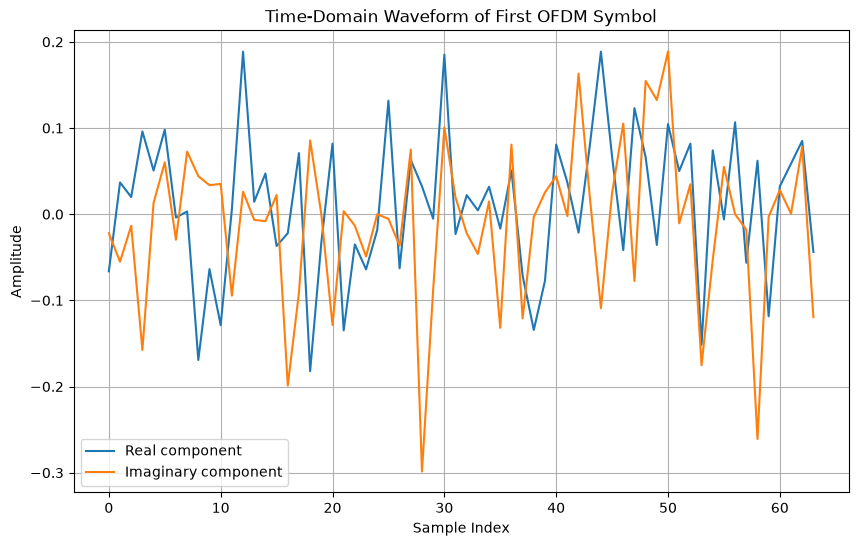

In [9]:
sample_index = np.arange(N_fft)

plt.figure(figsize=(10, 6))

plt.plot(
    sample_index,
    ofdm_time_symbols[0].real,
    label="Real component"
)

plt.plot(
    sample_index,
    ofdm_time_symbols[0].imag,
    label="Imaginary component"
)

plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.title("Time-Domain Waveform of First OFDM Symbol")
plt.grid(True)
plt.legend()

plt.savefig(
    "../results/ofdm_time_domain_waveform.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Ideal OFDM Receiver

In the ideal receiver, the time-domain OFDM signal is converted back to the frequency domain using the fast Fourier transform (FFT):

$$
x[n]
\;\xrightarrow{\mathrm{FFT}}\;
\hat{X}[k].
$$

Because no noise, multipath, or other channel distortion has been introduced, the FFT output should reproduce the original QPSK subcarrier symbols to within numerical floating-point precision.

In [10]:
# Convert the received time-domain OFDM symbols back to the frequency domain
recovered_frequency_symbols = np.fft.fft(
    ofdm_time_symbols,
    axis=1
)

# Flatten the OFDM blocks back into one symbol sequence
recovered_padded_symbols = recovered_frequency_symbols.reshape(-1)

# Remove the padding symbols that were added before transmission
recovered_qpsk_symbols = recovered_padded_symbols[:num_qpsk_symbols]

# Measure numerical reconstruction error
max_symbol_error = np.max(
    np.abs(qpsk_symbols - recovered_qpsk_symbols)
)

print("Original QPSK symbols:", len(qpsk_symbols))
print("Recovered QPSK symbols:", len(recovered_qpsk_symbols))
print(f"Maximum symbol reconstruction error: {max_symbol_error:.3e}")

# Verify that the FFT/IFFT chain reproduces the original symbols
assert np.allclose(
    qpsk_symbols,
    recovered_qpsk_symbols,
    atol=1e-12
)

Original QPSK symbols: 100
Recovered QPSK symbols: 100
Maximum symbol reconstruction error: 4.578e-16


In [11]:
# Demodulate the recovered QPSK symbols

ofdm_recovered_first_bits = (
    recovered_qpsk_symbols.real < 0
).astype(int)

ofdm_recovered_second_bits = (
    recovered_qpsk_symbols.imag < 0
).astype(int)

ofdm_recovered_bit_pairs = np.column_stack(
    (
        ofdm_recovered_first_bits,
        ofdm_recovered_second_bits
    )
)

ofdm_recovered_bits = ofdm_recovered_bit_pairs.reshape(-1)

# Calculate BER across the complete QPSK + OFDM transmitter-receiver chain
ofdm_bit_errors = np.count_nonzero(
    bits != ofdm_recovered_bits
)

ofdm_ber = ofdm_bit_errors / len(bits)

print("Transmitted bits:", len(bits))
print("Recovered bits:", len(ofdm_recovered_bits))
print("Bit errors:", ofdm_bit_errors)
print(f"OFDM bit error rate (BER): {ofdm_ber:.6f}")

assert np.array_equal(
    bits,
    ofdm_recovered_bits
)

Transmitted bits: 200
Recovered bits: 200
Bit errors: 0
OFDM bit error rate (BER): 0.000000


## Ideal OFDM Validation

The complete ideal transmitter-receiver chain successfully recovered all **200 transmitted bits** with **zero bit errors**.

The FFT recovered the original QPSK subcarrier symbols with a maximum numerical reconstruction error on the order of

$$
10^{-16},
$$

which is consistent with floating-point numerical precision rather than communication-system error.

Therefore, the ideal processing chain

$$
\text{bits}
\rightarrow
\text{QPSK}
\rightarrow
\text{IFFT}
\rightarrow
\text{FFT}
\rightarrow
\text{QPSK demodulation}
\rightarrow
\text{bits}
$$

has been validated before introducing channel impairments.

## Cyclic Prefix

In a multipath channel, delayed copies of one OFDM symbol can overlap with the next symbol and cause intersymbol interference.

OFDM commonly addresses this by copying the final samples of each time-domain OFDM symbol and placing them at the beginning.

If the useful OFDM symbol has $N$ samples and the cyclic-prefix length is $N_{\mathrm{CP}}$, the transmitted symbol becomes

$$
[x[N-N_{\mathrm{CP}}],\ldots,x[N-1],x[0],x[1],\ldots,x[N-1]].
$$

If the channel impulse response has $L_h$ samples, choosing

$$
N_{\mathrm{CP}} \ge L_h - 1
$$

prevents delayed energy from the previous OFDM symbol from contaminating the useful portion of the next symbol. After cyclic-prefix removal, this also allows the channel's linear convolution to behave as circular convolution over the useful OFDM symbol, enabling simple frequency-domain equalization.

For this experiment, a cyclic prefix of 16 samples is added to each 64-sample OFDM symbol.

In [12]:
# Cyclic-prefix length
N_cp = 16

# Copy the final N_cp samples of each OFDM symbol
cyclic_prefix = ofdm_time_symbols[:, -N_cp:]

# Prepend the cyclic prefix to each OFDM symbol
ofdm_with_cp = np.concatenate(
    (cyclic_prefix, ofdm_time_symbols),
    axis=1
)

print("Useful OFDM symbol length:", N_fft)
print("Cyclic-prefix length:", N_cp)
print("Transmitted OFDM symbol length:", ofdm_with_cp.shape[1])
print("Array shape with cyclic prefix:", ofdm_with_cp.shape)

Useful OFDM symbol length: 64
Cyclic-prefix length: 16
Transmitted OFDM symbol length: 80
Array shape with cyclic prefix: (2, 80)


### Cyclic-Prefix Removal

At the receiver, the cyclic prefix is discarded before the FFT is performed.

In the current ideal channel, adding and removing the cyclic prefix should not change the recovered data. This provides another validation step before multipath propagation is introduced.

In [13]:
# Ideal transmission: no channel distortion yet
received_with_cp = ofdm_with_cp.copy()

# Remove the cyclic prefix
received_without_cp = received_with_cp[:, N_cp:]

print("Received shape before CP removal:", received_with_cp.shape)
print("Received shape after CP removal:", received_without_cp.shape)

assert received_without_cp.shape == (num_ofdm_symbols, N_fft)

Received shape before CP removal: (2, 80)
Received shape after CP removal: (2, 64)


In [14]:
# Recover the frequency-domain OFDM symbols after CP removal
cp_recovered_frequency_symbols = np.fft.fft(
    received_without_cp,
    axis=1
)

cp_recovered_padded_symbols = cp_recovered_frequency_symbols.reshape(-1)

cp_recovered_qpsk_symbols = (
    cp_recovered_padded_symbols[:num_qpsk_symbols]
)

max_cp_symbol_error = np.max(
    np.abs(qpsk_symbols - cp_recovered_qpsk_symbols)
)

print(
    f"Maximum symbol error after CP add/remove: "
    f"{max_cp_symbol_error:.3e}"
)

assert np.allclose(
    qpsk_symbols,
    cp_recovered_qpsk_symbols,
    atol=1e-12
)

Maximum symbol error after CP add/remove: 4.578e-16


In [15]:
cp_first_bits = (
    cp_recovered_qpsk_symbols.real < 0
).astype(int)

cp_second_bits = (
    cp_recovered_qpsk_symbols.imag < 0
).astype(int)

cp_bit_pairs = np.column_stack(
    (cp_first_bits, cp_second_bits)
)

cp_recovered_bits = cp_bit_pairs.reshape(-1)

cp_bit_errors = np.count_nonzero(
    bits != cp_recovered_bits
)

cp_ber = cp_bit_errors / len(bits)

print("Bit errors after CP processing:", cp_bit_errors)
print(f"BER after CP processing: {cp_ber:.6f}")

assert np.array_equal(
    bits,
    cp_recovered_bits
)

Bit errors after CP processing: 0
BER after CP processing: 0.000000


## Cyclic-Prefix Validation

The cyclic prefix increased each transmitted OFDM symbol from **64 samples** to **80 samples** by prepending the final **16 samples** of the useful symbol.

At the receiver, removing the cyclic prefix restored the original 64-sample OFDM symbol.

After cyclic-prefix removal and FFT processing, the recovered QPSK symbols differed from the transmitted symbols by only approximately

$$
4.6\times10^{-16},
$$

which is consistent with floating-point numerical precision.

The complete transmitter-receiver chain with cyclic-prefix processing recovered all **200 transmitted bits** with **zero bit errors**:

$$
\mathrm{BER}=0.
$$

This validates the QPSK, OFDM, and cyclic-prefix processing stages under ideal-channel conditions. The next step is to introduce a multipath channel and study how the cyclic prefix and frequency-domain equalization protect the transmitted data.